# 🌾 AgriDash — Pemodelan Data Tanaman Pangan
### Kabupaten Kediri | 2020–2025

**Notebook ini mencakup 4 bagian:**
| # | Bagian | Model |
|---|--------|-------|
| 1 | Exploratory Data Analysis (EDA) | Visualisasi & Statistik |
| 2 | Clustering Kecamatan | K-Means + Agglomerative |
| 3 | Prediksi Time Series | ETS, ARIMA, Linear Regression |
| 4 | Rekomendasi Tanaman | Bayesian Scoring |

In [56]:
import json, os

BASE = os.getcwd()
NOTEBOOK_PATH = os.path.join(BASE, 'notebooks', '01_Modeling_Tanaman_Pangan.ipynb')
_id = 0

def _new_id():
    global _id; _id += 1
    return f"cell-{_id:04d}"

def _lines(text):
    raw = text.strip('\n')
    parts = raw.split('\n')
    return [p + '\n' for p in parts[:-1]] + ([parts[-1]] if parts[-1] else [])

def md(text):
    return {"cell_type":"markdown","id":_new_id(),"metadata":{},"source":_lines(text)}

def code(text):
    return {"cell_type":"code","execution_count":None,"id":_new_id(),
            "metadata":{},"outputs":[],"source":_lines(text)}

# ================================================================
cells = []
# ================================================================

## 1. SETUP ENVIRONMENT

In [57]:
## 1. Setup Environment
import subprocess, sys

PACKAGES = ['pandas','numpy','matplotlib','seaborn','scikit-learn','statsmodels','scipy']
for pkg in PACKAGES:
    try:
        __import__(pkg if pkg != 'scikit-learn' else 'sklearn')
    except ImportError:
        print(f"Installing {pkg}...")
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', pkg, '-q'])

print("✅ Semua library tersedia")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.arima.model import ARIMA
from scipy.cluster.hierarchy import dendrogram, linkage
import warnings
warnings.filterwarnings('ignore')

✅ Semua library tersedia


In [58]:
# ── Display & Style ──
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:.2f}')
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
sns.set_style('whitegrid')
sns.set_palette('Set2')

print("✅ Import berhasil")

# ================================================================
# KONFIGURASI PATH — Sesuaikan jika perlu
# ================================================================
import os

DATA_PATH   = '../data/raw/tanaman_pangan/Tanaman_Pangan_per_kecamatan.csv'
OUTPUT_DIR  = '../output/'

os.makedirs(OUTPUT_DIR, exist_ok=True)
print(f"Data    : {os.path.abspath(DATA_PATH)}")
print(f"Output  : {os.path.abspath(OUTPUT_DIR)}")

✅ Import berhasil
Data    : d:\SDT\Project Analitika Data\AgriDash-0.1\data\raw\tanaman_pangan\Tanaman_Pangan_per_kecamatan.csv
Output  : d:\SDT\Project Analitika Data\AgriDash-0.1\output


## 2. EDA (Explanatory Data Analysis)

In [59]:
## EDA
# 2.1 Load profil dataset
df = pd.read_csv(DATA_PATH)
print(f"{'='*55}")
print(f"  PROFIL DATASET TANAMAN PANGAN")
print(f"{'='*55}")
print(f"  Jumlah baris       : {len(df):,}")
print(f"  Jumlah kolom       : {df.shape[1]}")
print(f"  Rentang tahun      : {df['Tahun'].min()} - {df['Tahun'].max()}")
print(f"  Jumlah kecamatan   : {df['kecamatan'].nunique()}")
print(f"  Jenis tanaman      : {df['tanaman'].nunique()}")
print(f"  Missing values     : {df.isnull().sum().sum()}")
print(f"{'='*55}")
print(f"\\nList tanaman: {sorted(df['tanaman'].unique().tolist())}")
print(f"\\nList kecamatan ({df['kecamatan'].nunique()}):")
print(sorted(df['kecamatan'].unique().tolist()))
df.head(8)

  PROFIL DATASET TANAMAN PANGAN
  Jumlah baris       : 780
  Jumlah kolom       : 6
  Rentang tahun      : 2020 - 2025
  Jumlah kecamatan   : 26
  Jenis tanaman      : 5
  Missing values     : 0
\nList tanaman: ['Kacang Tanah', 'Kedelai', 'Ketela Pohon', 'Padi', 'Ubi Jalar']
\nList kecamatan (26):
['Badas', 'Banyakan', 'Gampengrejo', 'Grogol', 'Gurah', 'Kandangan', 'Kandat', 'Kayenkidul', 'Kepung', 'Kras', 'Kunjang', 'Mojo', 'Ngadiluwih', 'Ngancar', 'Ngasem', 'Pagu', 'Papar', 'Pare', 'Plemahan', 'Plosoklaten', 'Puncu', 'Purwoasri', 'Ringinrejo', 'Semen', 'Tarokan', 'Wates']


,Tahun,kecamatan,tanaman,luas_panen_ha,produksi_ton,produktivitas_kuintal_ha
0,2020,Badas,Kacang Tanah,0.96,1.71,17.88
1,2021,Badas,Kacang Tanah,0.85,1.46,17.16
2,2022,Badas,Kacang Tanah,0.88,1.58,17.94
3,2023,Badas,Kacang Tanah,0.79,1.41,17.77
4,2024,Badas,Kacang Tanah,0.82,1.44,17.55
5,2025,Badas,Kacang Tanah,0.75,1.32,17.60
6,2020,Badas,Kedelai,5.92,7.65,12.92
7,2021,Badas,Kedelai,6.94,8.69,12.52


In [60]:
# 2.2 Statistik Deskriptif per Tanaman"
for t in sorted(df['tanaman'].unique()):
    sub = df[df['tanaman'] == t]
    print(f"\\n{'─'*55}")
    print(f"  {t.upper()}")
    print(f"{'─'*55}")
    desc = sub[['luas_panen_ha','produksi_ton','produktivitas_kuintal_ha']].describe().round(2)
    print(desc)

\n───────────────────────────────────────────────────────
  KACANG TANAH
───────────────────────────────────────────────────────
       luas_panen_ha  produksi_ton  produktivitas_kuintal_ha
count         156.00        156.00                    156.00
mean           18.50         32.42                     17.16
std            23.32         40.90                      2.52
min             0.00          0.00                      0.00
25%             2.60          4.61                     17.08
50%             7.16         12.41                     17.66
75%            23.92         42.60                     17.82
max            87.55        163.97                     19.48
\n───────────────────────────────────────────────────────
  KEDELAI
───────────────────────────────────────────────────────
       luas_panen_ha  produksi_ton  produktivitas_kuintal_ha
count         156.00        156.00                    156.00
mean            0.33          0.44                     11.26
std            

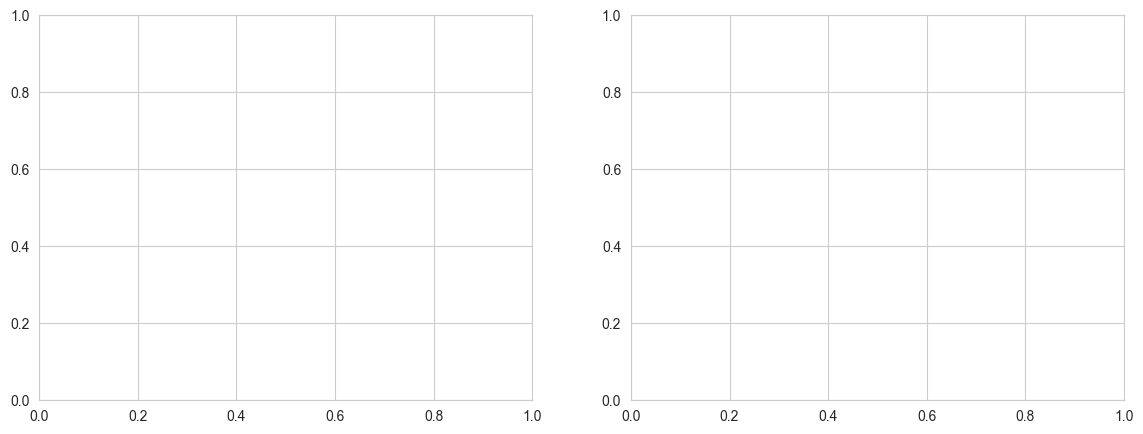

In [61]:
# 2.3 Visualisasi — Produksi & Produktivitas per Tanaman
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colors = sns.color_palette('Set2', df['tanaman'].nunique())

In [62]:
# ── Total Produksi per Tanaman ──
prod_tan = df.groupby('tanaman')['produksi_ton'].sum().sort_values(ascending=False)
bars = axes[0].bar(prod_tan.index, prod_tan.values, color=colors, edgecolor='white', linewidth=0.8)
axes[0].set_title('Total Produksi per Jenis Tanaman (2020–2025)')
axes[0].set_xlabel('Jenis Tanaman'); axes[0].set_ylabel('Produksi (Ton)')
axes[0].tick_params(axis='x', rotation=15)
for bar, v in zip(bars, prod_tan.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + prod_tan.max()*0.01,
                 f'{v:,.0f}', ha='center', va='bottom', fontsize=9, fontweight='bold')


In [63]:
# ── Rata-rata Produktivitas per Tanaman ──
prod_v = df.groupby('tanaman')['produktivitas_kuintal_ha'].mean().sort_values(ascending=False)
bars2 = axes[1].bar(prod_v.index, prod_v.values, color=colors[::-1], edgecolor='white', linewidth=0.8)
axes[1].set_title('Rata-rata Produktivitas per Jenis Tanaman')
axes[1].set_xlabel('Jenis Tanaman'); axes[1].set_ylabel('Produktivitas (Kw/Ha)')
axes[1].tick_params(axis='x', rotation=15)
for bar, v in zip(bars2, prod_v.values):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + prod_v.max()*0.01,
                 f'{v:.1f}', ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.suptitle('Overview Komoditas Tanaman Pangan — Kabupaten Kediri', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(OUTPUT_DIR + 'eda_01_produksi_per_tanaman.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"✅ Saved: eda_01_produksi_per_tanaman.png")

<Figure size 1200x500 with 0 Axes>

✅ Saved: eda_01_produksi_per_tanaman.png


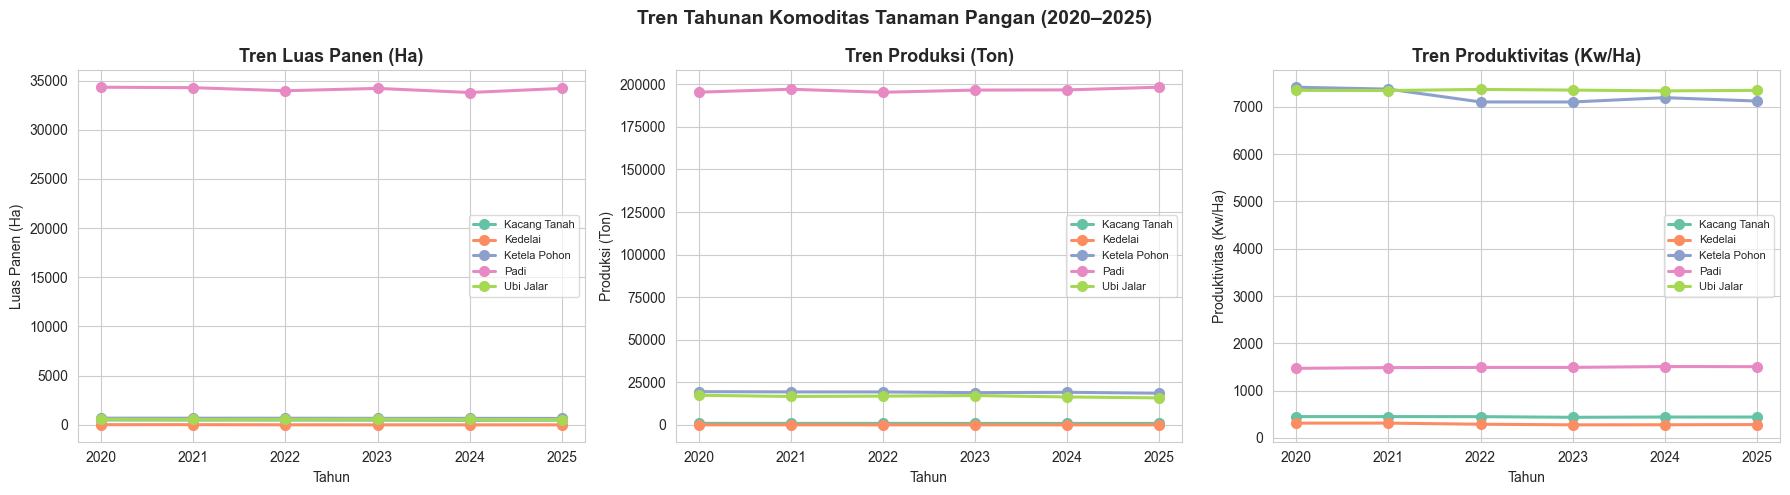

In [64]:
# 2.4 Visualisasi — Tren Tahunan per Tanaman
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
metrics = [
    ('luas_panen_ha',           'Luas Panen (Ha)'),
    ('produksi_ton',            'Produksi (Ton)'),
    ('produktivitas_kuintal_ha','Produktivitas (Kw/Ha)'),
]
tanaman_list = sorted(df['tanaman'].unique())
colors = sns.color_palette('Set2', len(tanaman_list))

for ax, (col, label) in zip(axes, metrics):
    for i, t in enumerate(tanaman_list):
        sub = df[df['tanaman'] == t].groupby('Tahun')[col].sum()
        ax.plot(sub.index, sub.values, marker='o', label=t,
                color=colors[i], linewidth=2.2, markersize=7)
    ax.set_title(f'Tren {label}'); ax.set_xlabel('Tahun'); ax.set_ylabel(label)
    ax.legend(fontsize=8, framealpha=0.7)
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))

plt.suptitle('Tren Tahunan Komoditas Tanaman Pangan (2020–2025)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(OUTPUT_DIR + 'eda_02_trend_tahunan.png', dpi=150, bbox_inches='tight')
plt.show()

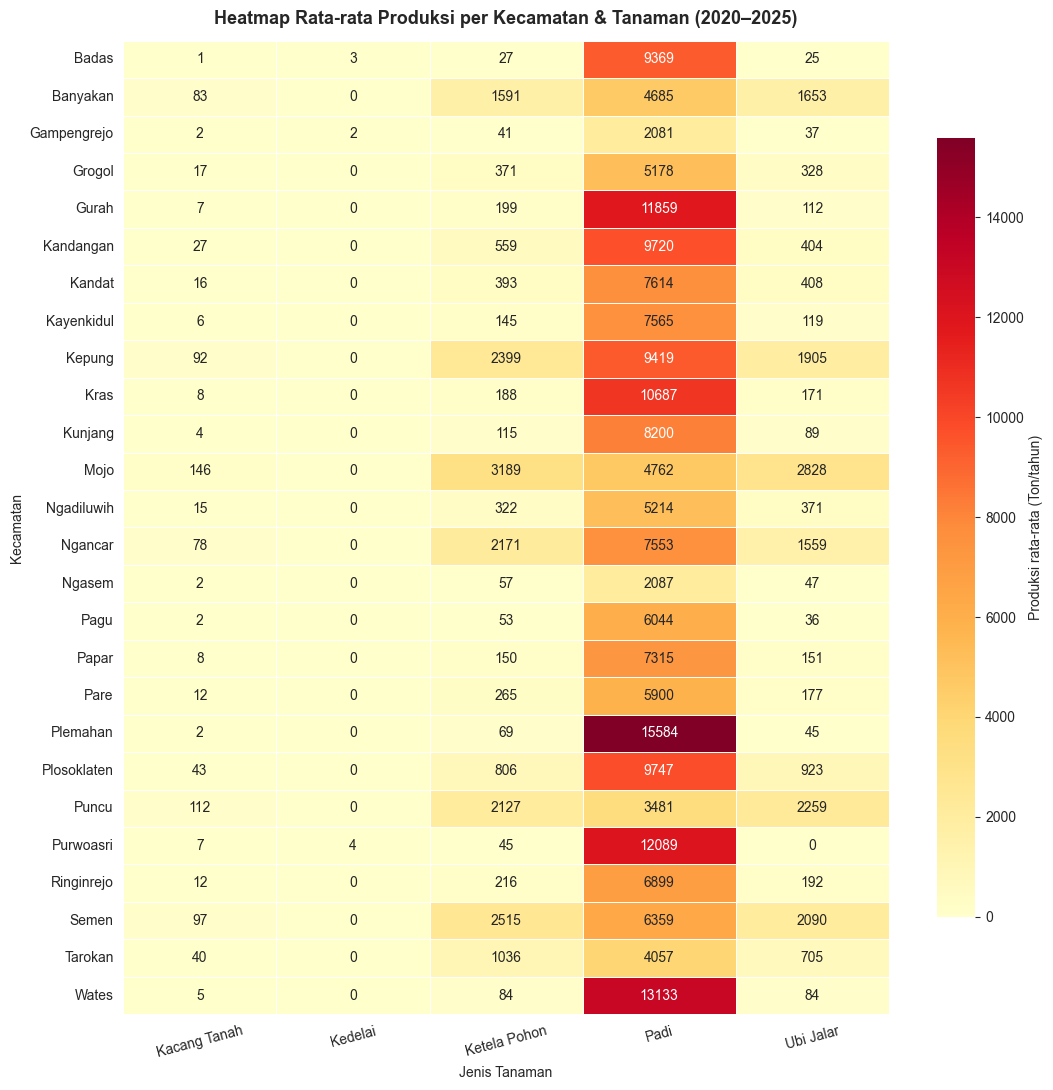

In [65]:
# 2.5 Heatmap — Produksi rata-rata per Kecamatan
pivot_hm = df.groupby(['kecamatan','tanaman'])['produksi_ton'].mean().unstack(fill_value=0).round(0)

fig, ax = plt.subplots(figsize=(11, 11))
sns.heatmap(pivot_hm, annot=True, fmt='.0f', cmap='YlOrRd',
            linewidths=0.4, linecolor='white', ax=ax,
            cbar_kws={'label': 'Produksi rata-rata (Ton/tahun)', 'shrink': 0.8})
ax.set_title('Heatmap Rata-rata Produksi per Kecamatan & Tanaman (2020–2025)',
             fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Jenis Tanaman'); ax.set_ylabel('Kecamatan')
ax.tick_params(axis='x', rotation=15)
plt.tight_layout()
plt.savefig(OUTPUT_DIR + 'eda_03_heatmap_kecamatan.png', dpi=150, bbox_inches='tight')
plt.show()

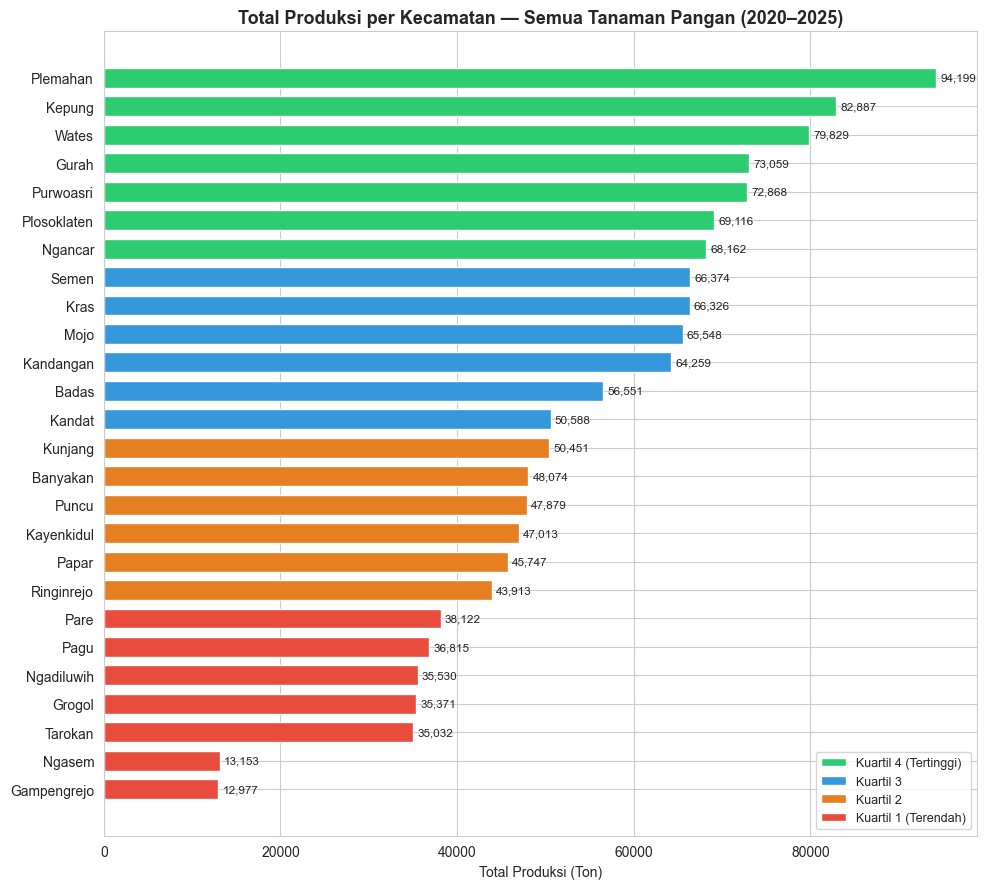

In [66]:
# 2.6 Top Kecamatan berdasarkan Total Produksi
top_kec = df.groupby('kecamatan')['produksi_ton'].sum().sort_values(ascending=True)
color_arr = ['#2ecc71' if v >= top_kec.quantile(0.75) else
             '#3498db' if v >= top_kec.quantile(0.5) else
             '#e67e22' if v >= top_kec.quantile(0.25) else '#e74c3c'
             for v in top_kec.values]

fig, ax = plt.subplots(figsize=(10, 9))
bars = ax.barh(top_kec.index, top_kec.values, color=color_arr, edgecolor='white', height=0.7)
ax.set_title('Total Produksi per Kecamatan — Semua Tanaman Pangan (2020–2025)',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Total Produksi (Ton)')

for bar, v in zip(bars, top_kec.values):
    ax.text(bar.get_width() + top_kec.max()*0.005, bar.get_y() + bar.get_height()/2,
            f'{v:,.0f}', va='center', fontsize=8.5)

# Legenda kategori
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#2ecc71', label='Kuartil 4 (Tertinggi)'),
    Patch(facecolor='#3498db', label='Kuartil 3'),
    Patch(facecolor='#e67e22', label='Kuartil 2'),
    Patch(facecolor='#e74c3c', label='Kuartil 1 (Terendah)'),
]
ax.legend(handles=legend_elements, loc='lower right', fontsize=9)
plt.tight_layout()
plt.savefig(OUTPUT_DIR + 'eda_04_top_kecamatan.png', dpi=150, bbox_inches='tight')
plt.show()

## 3. CLUSTERING

In [67]:
## 3.1 Persiapan Feature Matrix\n\nFeature matrix: **rata-rata produksi per kecamatan per tanaman** (26 baris × 5 kolom)"))
# Pivot: rata-rata produksi per kecamatan × per tanaman
pivot_cl = df.groupby(['kecamatan','tanaman'])['produksi_ton'].mean().unstack(fill_value=0)
print("Feature matrix untuk clustering:")
print(f"Shape: {pivot_cl.shape}  →  ({pivot_cl.shape[0]} kecamatan × {pivot_cl.shape[1]} tanaman)")
print()
print(pivot_cl.round(2))

# StandardScaler — normalisasi fitur agar skala setara
scaler = StandardScaler()
X_scaled = scaler.fit_transform(pivot_cl)

print("Data setelah StandardScaler (5 baris pertama):")
pd.DataFrame(X_scaled, index=pivot_cl.index, columns=pivot_cl.columns).round(3).head()

Feature matrix untuk clustering:
Shape: (26, 5)  →  (26 kecamatan × 5 tanaman)

tanaman      Kacang Tanah  Kedelai  Ketela Pohon     Padi  Ubi Jalar
kecamatan                                                           
Badas                1.49     2.72         26.57  9369.14      25.16
Banyakan            82.67     0.25       1590.89  4685.50    1653.04
Gampengrejo          2.00     2.13         40.68  2081.12      36.93
Grogol              17.19     0.05        371.32  5178.33     328.34
Gurah                6.51     0.02        198.95 11859.29     111.79
Kandangan           27.22     0.06        558.52  9719.67     404.31
Kandat              15.79     0.06        392.72  7614.49     408.19
Kayenkidul           6.36     0.02        145.36  7564.55     119.14
Kepung              91.82     0.27       2398.54  9419.09    1904.76
Kras                 8.02     0.03        188.44 10686.74     171.17
Kunjang              4.26     0.01        115.26  8199.54      89.41
Mojo               145.

tanaman,Kacang Tanah,Kedelai,Ketela Pohon,Padi,Ubi Jalar
kecamatan,,,,,
Badas,-0.76,2.37,-0.76,0.55,-0.75
Banyakan,1.24,-0.20,0.92,-0.87,1.23
Gampengrejo,-0.75,1.76,-0.74,-1.66,-0.74
Grogol,-0.38,-0.40,-0.39,-0.72,-0.38
Gurah,-0.64,-0.43,-0.57,1.30,-0.65


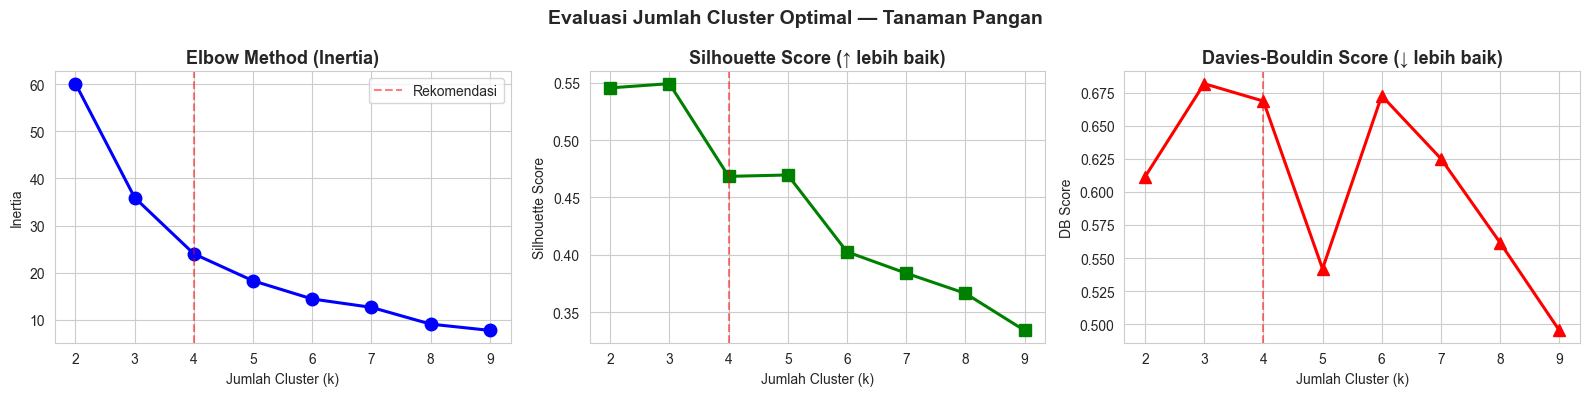

\nRingkasan Metrik per k:
  k |   Silhouette |  Davies-Bouldin
-----------------------------------
  2 |       0.5454 |          0.6114
  3 |       0.5491 |          0.6819 ◄ optimal?
  4 |       0.4684 |          0.6687
  5 |       0.4696 |          0.5419
  6 |       0.4027 |          0.6728
  7 |       0.3841 |          0.6252
  8 |       0.3665 |          0.5616
  9 |       0.3343 |          0.4952


In [68]:
## 3.2 Penentuan Jumlah Cluster Optimal"))
# ── Elbow Method + Silhouette + Davies-Bouldin ──
inertias, silhouettes, db_scores = [], [], []
K_range = range(2, 10)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels))
    db_scores.append(davies_bouldin_score(X_scaled, labels))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].plot(K_range, inertias, 'bo-', linewidth=2.2, markersize=9)
axes[0].set_title('Elbow Method (Inertia)')
axes[0].set_xlabel('Jumlah Cluster (k)'); axes[0].set_ylabel('Inertia')
# Tandai titik optimal
axes[0].axvline(x=4, color='red', linestyle='--', alpha=0.5, label='Rekomendasi')
axes[0].legend()

axes[1].plot(K_range, silhouettes, 'gs-', linewidth=2.2, markersize=9)
axes[1].set_title('Silhouette Score (↑ lebih baik)')
axes[1].set_xlabel('Jumlah Cluster (k)'); axes[1].set_ylabel('Silhouette Score')
axes[1].axvline(x=4, color='red', linestyle='--', alpha=0.5)

axes[2].plot(K_range, db_scores, 'r^-', linewidth=2.2, markersize=9)
axes[2].set_title('Davies-Bouldin Score (↓ lebih baik)')
axes[2].set_xlabel('Jumlah Cluster (k)'); axes[2].set_ylabel('DB Score')
axes[2].axvline(x=4, color='red', linestyle='--', alpha=0.5)

plt.suptitle('Evaluasi Jumlah Cluster Optimal — Tanaman Pangan', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(OUTPUT_DIR + 'cluster_01_elbow_evaluation.png', dpi=150, bbox_inches='tight')
plt.show()

print("\\nRingkasan Metrik per k:")
print(f"{'k':>3} | {'Silhouette':>12} | {'Davies-Bouldin':>15}")
print("-" * 35)
for k, sil, db in zip(K_range, silhouettes, db_scores):
    mark = " ◄ optimal?" if k == silhouettes.index(max(silhouettes)) + 2 else ""
    print(f"{k:>3} | {sil:>12.4f} | {db:>15.4f}{mark}")

In [69]:
## 3.3 K-Means Clustering"
# ================================================================
# ⬇️  UBAH nilai K_OPTIMAL setelah melihat elbow plot di atas!
# ================================================================
K_OPTIMAL = 4   # <-- sesuaikan berdasarkan hasil elbow + silhouette

km_final = KMeans(n_clusters=K_OPTIMAL, random_state=42, n_init=10)
labels_km = km_final.fit_predict(X_scaled)

sil_km = silhouette_score(X_scaled, labels_km)
db_km  = davies_bouldin_score(X_scaled, labels_km)

print(f"K-Means — k = {K_OPTIMAL}")
print(f"  Silhouette Score : {sil_km:.4f}  (semakin mendekati 1 = semakin baik)")
print(f"  Davies-Bouldin   : {db_km:.4f}   (semakin mendekati 0 = semakin baik)")
print()

# Distribusi kecamatan per cluster
result_km = pd.DataFrame({'kecamatan': pivot_cl.index, 'cluster_kmeans': labels_km})
print("Distribusi cluster:")
for c in sorted(result_km['cluster_kmeans'].unique()):
    kecs = sorted(result_km[result_km['cluster_kmeans'] == c]['kecamatan'].tolist())
    print(f"  Cluster {c} ({len(kecs)} kec): {kecs}")

K-Means — k = 4
  Silhouette Score : 0.4684  (semakin mendekati 1 = semakin baik)
  Davies-Bouldin   : 0.6687   (semakin mendekati 0 = semakin baik)

Distribusi cluster:
  Cluster 0 (6 kec): ['Gurah', 'Kandangan', 'Kras', 'Plemahan', 'Plosoklaten', 'Wates']
  Cluster 1 (6 kec): ['Banyakan', 'Kepung', 'Mojo', 'Ngancar', 'Puncu', 'Semen']
  Cluster 2 (3 kec): ['Badas', 'Gampengrejo', 'Purwoasri']
  Cluster 3 (11 kec): ['Grogol', 'Kandat', 'Kayenkidul', 'Kunjang', 'Ngadiluwih', 'Ngasem', 'Pagu', 'Papar', 'Pare', 'Ringinrejo', 'Tarokan']


In [70]:
## 2.4 Interpretasi Centroid K-Means

# Kembalikan centroid ke skala asli untuk interpretasi
centroid_df = pd.DataFrame(
    scaler.inverse_transform(km_final.cluster_centers_),
    columns=pivot_cl.columns
).round(2)
centroid_df.index.name = 'cluster'
print("Rata-rata produksi (ton/tahun) per tanaman di tiap cluster:")
print(centroid_df)
print()
print("💡 Panduan labeling:")
print("   Cluster dengan nilai PADI tinggi → dominan penghasil padi")
print("   Cluster dengan nilai mendekati 0 → kecamatan tidak banyak memproduksi komoditas tsb")
print()
print("   ➡️  Lanjut ke cell berikutnya untuk memberi label bermakna pada tiap cluster")

Rata-rata produksi (ton/tahun) per tanaman di tiap cluster:
tanaman  Kacang Tanah  Kedelai  Ketela Pohon     Padi  Ubi Jalar
cluster                                                         
0               15.28     0.05        317.41 11788.27     289.79
1              101.12     0.29       2331.91  6043.37    2048.99
2                3.57     2.98         37.34  7846.28      20.70
3               12.16     0.04        284.02  6006.61     238.59

💡 Panduan labeling:
   Cluster dengan nilai PADI tinggi → dominan penghasil padi
   Cluster dengan nilai mendekati 0 → kecamatan tidak banyak memproduksi komoditas tsb

   ➡️  Lanjut ke cell berikutnya untuk memberi label bermakna pada tiap cluster


Agglomerative Clustering — k = 4
  Silhouette Score : 0.4684
  Davies-Bouldin   : 0.6687


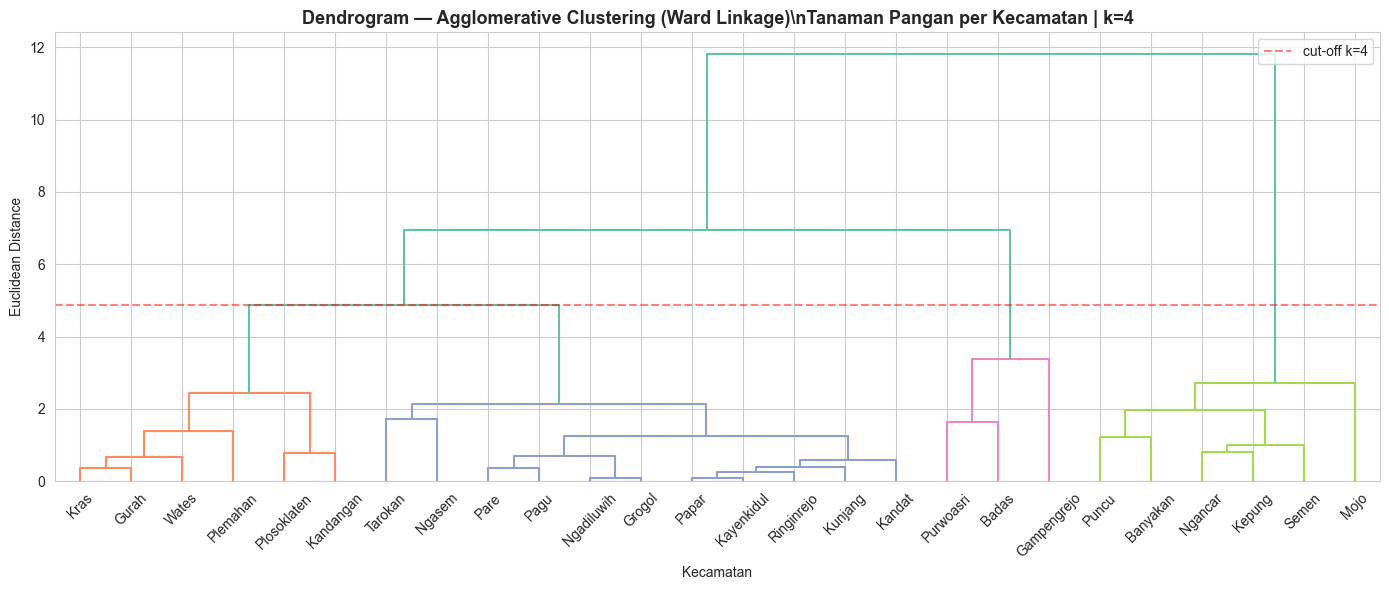

In [71]:
## 3.5 Agglomerative Clustering + Dendrogram

agg = AgglomerativeClustering(n_clusters=K_OPTIMAL, linkage='ward')
labels_agg = agg.fit_predict(X_scaled)

sil_agg = silhouette_score(X_scaled, labels_agg)
db_agg  = davies_bouldin_score(X_scaled, labels_agg)

print(f"Agglomerative Clustering — k = {K_OPTIMAL}")
print(f"  Silhouette Score : {sil_agg:.4f}")
print(f"  Davies-Bouldin   : {db_agg:.4f}")

# Dendrogram
linked = linkage(X_scaled, method='ward')
fig, ax = plt.subplots(figsize=(14, 6))
dendrogram(
    linked,
    labels=pivot_cl.index.tolist(),
    orientation='top',
    distance_sort='descending',
    show_leaf_counts=True,
    ax=ax,
    color_threshold=linked[-K_OPTIMAL+1, 2],
    leaf_rotation=45
)
ax.set_title(
    f'Dendrogram — Agglomerative Clustering (Ward Linkage)\\nTanaman Pangan per Kecamatan | k={K_OPTIMAL}',
    fontsize=13, fontweight='bold'
)
ax.set_xlabel('Kecamatan'); ax.set_ylabel('Euclidean Distance')
ax.axhline(y=linked[-K_OPTIMAL+1, 2], color='red', linestyle='--', alpha=0.5, label=f'cut-off k={K_OPTIMAL}')
ax.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR + 'cluster_02_dendrogram.png', dpi=150, bbox_inches='tight')
plt.show()

In [72]:
## 3.6 Perbandingan K-Means vs Agglomerative

comparison_cl = pd.DataFrame({
    'Metode'              : ['K-Means', 'Agglomerative (Ward)'],
    'Silhouette (↑)'      : [round(sil_km, 4), round(sil_agg, 4)],
    'Davies-Bouldin (↓)'  : [round(db_km, 4), round(db_agg, 4)],
    'Digunakan untuk'     : ['Dashboard Tableau (label diskret)', 'Validasi & Laporan (dendrogram)'],
})
print(comparison_cl.to_string(index=False))
print()
if sil_km >= sil_agg:
    print("✅ K-Means dipilih sebagai model utama (Silhouette lebih tinggi atau sama)")
else:
    print("ℹ️  Agglomerative punya Silhouette lebih tinggi — pertimbangkan sebagai model utama")

              Metode  Silhouette (↑)  Davies-Bouldin (↓)                   Digunakan untuk
             K-Means            0.47                0.67 Dashboard Tableau (label diskret)
Agglomerative (Ward)            0.47                0.67   Validasi & Laporan (dendrogram)

✅ K-Means dipilih sebagai model utama (Silhouette lebih tinggi atau sama)


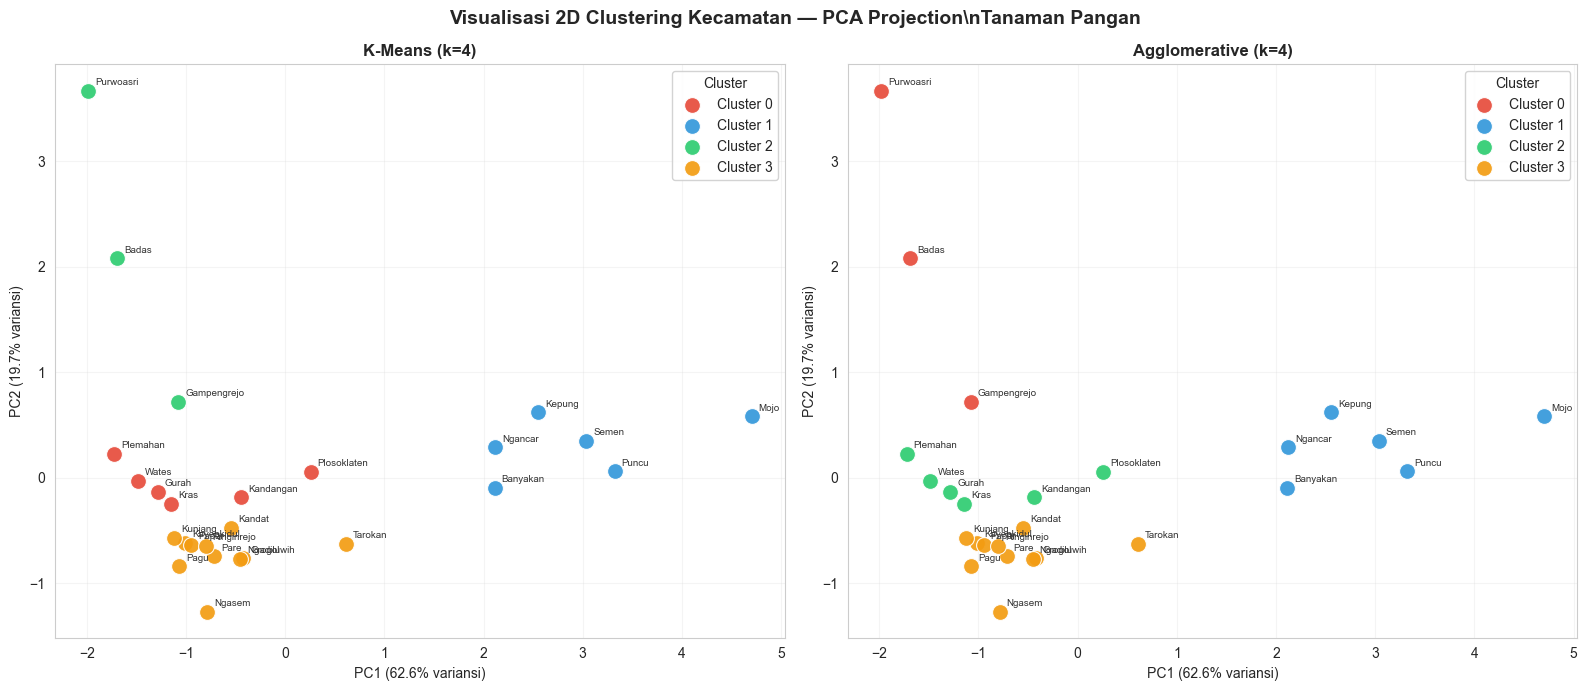

In [73]:
## 3.7 Visualisasi Cluster (PCA 2D)

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
kec_names = pivot_cl.index.tolist()

COLORS_CLUSTER = ['#e74c3c','#3498db','#2ecc71','#f39c12','#9b59b6','#1abc9c','#e67e22','#34495e']

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for ax, (labels, title) in zip(axes, [
    (labels_km,  f'K-Means (k={K_OPTIMAL})'),
    (labels_agg, f'Agglomerative (k={K_OPTIMAL})'),
]):
    for c in sorted(np.unique(labels)):
        mask = labels == c
        ax.scatter(X_pca[mask, 0], X_pca[mask, 1],
                   c=COLORS_CLUSTER[c], label=f'Cluster {c}',
                   s=130, edgecolors='white', linewidth=0.8, alpha=0.92, zorder=3)
        for i, name in enumerate(kec_names):
            if mask[i]:
                ax.annotate(name, (X_pca[i, 0], X_pca[i, 1]),
                            textcoords='offset points', xytext=(5, 4),
                            fontsize=7, color='#333333')

    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variansi)')
    ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variansi)')
    ax.legend(title='Cluster', framealpha=0.85)
    ax.grid(True, alpha=0.2)

plt.suptitle('Visualisasi 2D Clustering Kecamatan — PCA Projection\\nTanaman Pangan',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(OUTPUT_DIR + 'cluster_03_pca_2d.png', dpi=150, bbox_inches='tight')
plt.show()

In [74]:
## 3.8 Labeling Cluster & Export Output

# ================================================================
# ⬇️  WAJIB disesuaikan berdasarkan hasil centroid_df di atas!
# ================================================================
CLUSTER_LABELS = {
    0: 'Potensi Rendah',
    1: 'Potensi Sedang',
    2: 'Potensi Tinggi',
    3: 'Potensi Sangat Tinggi',
}
# Jika K_OPTIMAL != 4, tambahkan/kurangi key

result_cl = pivot_cl.copy().reset_index()
result_cl['cluster_id']          = labels_km
result_cl['cluster_agg_id']      = labels_agg
result_cl['label_cluster']       = result_cl['cluster_id'].map(CLUSTER_LABELS)
result_cl['label_cluster_agg']   = result_cl['cluster_agg_id'].map(CLUSTER_LABELS)

# Tambahkan info tambahan: total produksi rata-rata
result_cl['total_produksi_mean'] = pivot_cl.sum(axis=1).values.round(2)

print("Hasil Clustering Kecamatan:")
print(result_cl[['kecamatan','cluster_id','label_cluster','total_produksi_mean']].to_string(index=False))

# Export
out_path_cl = OUTPUT_DIR + 'output_clustering_pangan.csv'
result_cl.to_csv(out_path_cl, index=False)
print(f"\\n✅ Tersimpan: {out_path_cl}")
print(f"   Kolom: {result_cl.columns.tolist()}")

Hasil Clustering Kecamatan:
  kecamatan  cluster_id         label_cluster  total_produksi_mean
      Badas           2        Potensi Tinggi              9425.09
   Banyakan           1        Potensi Sedang              8012.34
Gampengrejo           2        Potensi Tinggi              2162.87
     Grogol           3 Potensi Sangat Tinggi              5895.24
      Gurah           0        Potensi Rendah             12176.56
  Kandangan           0        Potensi Rendah             10709.78
     Kandat           3 Potensi Sangat Tinggi              8431.25
 Kayenkidul           3 Potensi Sangat Tinggi              7835.42
     Kepung           1        Potensi Sedang             13814.48
       Kras           0        Potensi Rendah             11054.39
    Kunjang           3 Potensi Sangat Tinggi              8408.48
       Mojo           1        Potensi Sedang             10924.62
 Ngadiluwih           3 Potensi Sangat Tinggi              5921.60
    Ngancar           1        Pot

## 4. TIME SERIES

## 4.1 Strategi & Pembagian Data

| Split | Tahun | Keterangan |
|-------|-------|-----------|
| **Train** | 2020–2024 | 5 titik waktu per kombinasi |
| **Test** | 2025 | Validasi akurasi model |
| **Forecast** | 2026–2027 | Output untuk dashboard |

> ⚠️ Karena hanya 6 tahun, 3 metode ringan dibandingkan:  
> **ETS** (Exponential Smoothing) · **ARIMA(1,1,0)** · **Linear Regression**  
> Model terbaik per kombinasi dipilih berdasarkan MAPE terendah.

In [75]:
TARGET_COLS  = ['luas_panen_ha', 'produksi_ton']
TRAIN_YEARS  = [2020, 2021, 2022, 2023, 2024]
TEST_YEAR    = 2025
FORECAST_YRS = [2026, 2027]

tanaman_list   = sorted(df['tanaman'].unique())
kecamatan_list = sorted(df['kecamatan'].unique())

print(f"Target variabel    : {TARGET_COLS}")
print(f"Train              : {TRAIN_YEARS}")
print(f"Test               : {TEST_YEAR}")
print(f"Forecast           : {FORECAST_YRS}")
print(f"Jumlah kombinasi   : {len(tanaman_list)} tanaman × {len(kecamatan_list)} kecamatan = {len(tanaman_list)*len(kecamatan_list)}")

Target variabel    : ['luas_panen_ha', 'produksi_ton']
Train              : [2020, 2021, 2022, 2023, 2024]
Test               : 2025
Forecast           : [2026, 2027]
Jumlah kombinasi   : 5 tanaman × 26 kecamatan = 130


In [76]:
## 4.2 Fungsi Model & Evaluasi

def ets_forecast(series, steps=1):
    # Holt's Exponential Smoothing dengan trend additive
    try:
        if len(series) < 3 or series.sum() == 0:
            return [float(series[-1])] * steps
        m = ExponentialSmoothing(series, trend='add', initialization_method='estimated').fit()
        return [max(0, v) for v in m.forecast(steps)]
    except:
        return [max(0, float(np.mean(series)))] * steps

def arima_forecast(series, steps=1):
    # ARIMA dengan order otomatis fallback
    for order in [(1,1,0), (1,0,0), (0,1,0)]:
        try:
            if len(series) < 4 or series.sum() == 0:
                return [float(series[-1])] * steps
            m = ARIMA(series, order=order).fit()
            return [max(0, v) for v in m.forecast(steps)]
        except:
            continue
    return [max(0, float(np.mean(series)))] * steps

def lr_forecast(years_tr, series_tr, years_fc):
    # Linear Regression sederhana
    try:
        lr = LinearRegression()
        lr.fit(np.array(years_tr).reshape(-1,1), np.array(series_tr))
        preds = lr.predict(np.array(years_fc).reshape(-1,1))
        return [max(0, v) for v in preds]
    except:
        return [max(0, float(np.mean(series_tr)))] * len(years_fc)

def eval_metrics(actual, predicted):
    # Hitung MAE, RMSE, MAPE
    a, p = np.array(actual, dtype=float), np.array(predicted, dtype=float)
    mae  = float(np.mean(np.abs(a - p)))
    rmse = float(np.sqrt(np.mean((a - p)**2)))
    mape = float(np.mean(np.abs((a - p) / (np.abs(a) + 1e-6))) * 100)
    return {'MAE': round(mae,4), 'RMSE': round(rmse,4), 'MAPE': round(mape,2)}

print("✅ Fungsi model siap")

✅ Fungsi model siap


In [77]:
## 4.3 Perbandingan Model — Train/Test Split"))

comp_rows = []

for target_col in TARGET_COLS:
    for kec in kecamatan_list:
        for tan in tanaman_list:
            sub = df[(df['kecamatan']==kec) & (df['tanaman']==tan)].sort_values('Tahun')

            train_data = sub[sub['Tahun'].isin(TRAIN_YEARS)]
            test_data  = sub[sub['Tahun'] == TEST_YEAR]

            if len(test_data) == 0 or len(train_data) < 3:
                continue

            series_tr = train_data[target_col].values.astype(float)
            years_tr  = train_data['Tahun'].values.tolist()
            actual    = float(test_data[target_col].values[0])

            p_ets   = ets_forecast(series_tr, 1)[0]
            p_arima = arima_forecast(series_tr, 1)[0]
            p_lr    = lr_forecast(years_tr, series_tr.tolist(), [TEST_YEAR])[0]

            m_ets   = eval_metrics([actual], [p_ets])
            m_arima = eval_metrics([actual], [p_arima])
            m_lr    = eval_metrics([actual], [p_lr])

            comp_rows.append({
                'kecamatan': kec, 'tanaman': tan, 'target': target_col,
                'actual_2025'  : round(actual, 3),
                'pred_ets'     : round(p_ets, 3),
                'pred_arima'   : round(p_arima, 3),
                'pred_lr'      : round(p_lr, 3),
                'mape_ets'     : m_ets['MAPE'],
                'mape_arima'   : m_arima['MAPE'],
                'mape_lr'      : m_lr['MAPE'],
                'mae_ets'      : m_ets['MAE'],
                'mae_arima'    : m_arima['MAE'],
                'mae_lr'       : m_lr['MAE'],
            })

comp_df = pd.DataFrame(comp_rows)
comp_df['best_model'] = comp_df[['mape_ets','mape_arima','mape_lr']].idxmin(axis=1).str.replace('mape_','')

print(f"Total kombinasi dievaluasi : {len(comp_df)}")
print()
print("RATA-RATA MAPE PER METODE (seluruh kombinasi):")
for m, col in [('ETS','mape_ets'),('ARIMA','mape_arima'),('Linear Reg','mape_lr')]:
    print(f"  {m:<12}: {comp_df[col].mean():.2f}%")
print()
print("Frekuensi model terbaik per kombinasi:")
print(comp_df['best_model'].value_counts().to_string())

Total kombinasi dievaluasi : 260

RATA-RATA MAPE PER METODE (seluruh kombinasi):
  ETS         : 9.11%
  ARIMA       : 8.35%
  Linear Reg  : 8.51%

Frekuensi model terbaik per kombinasi:
best_model
arima    116
ets      110
lr        34


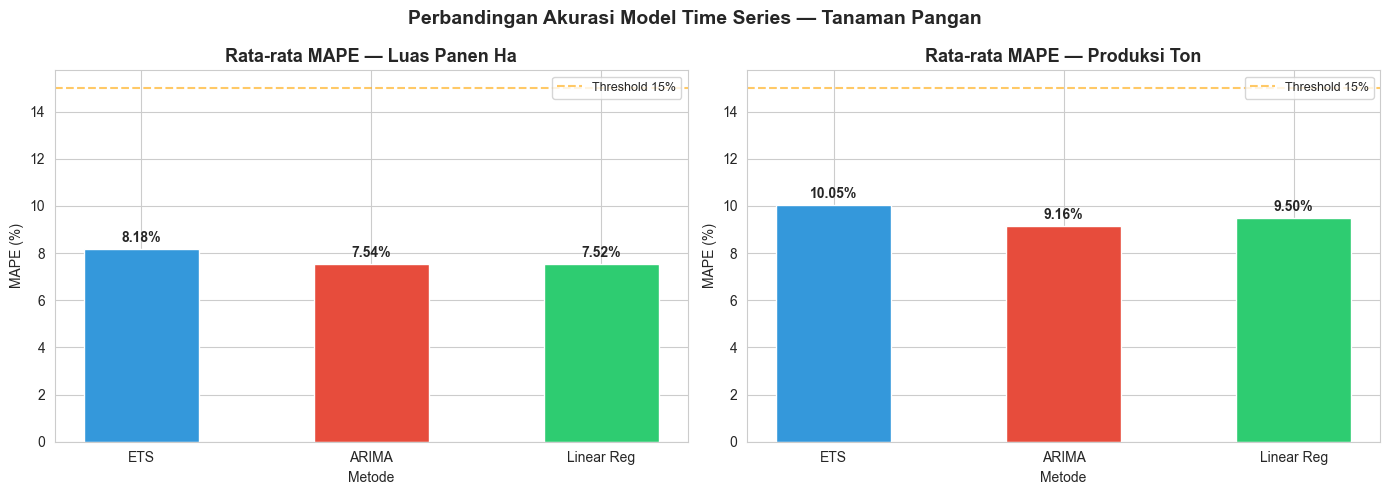

In [78]:
## 4.4 Visualisasi Perbandingan MAPE

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, target in zip(axes, TARGET_COLS):
    sub = comp_df[comp_df['target'] == target]
    mape_means = {
        'ETS'       : sub['mape_ets'].mean(),
        'ARIMA'     : sub['mape_arima'].mean(),
        'Linear Reg': sub['mape_lr'].mean(),
    }
    bars = ax.bar(mape_means.keys(), mape_means.values(),
                  color=['#3498db','#e74c3c','#2ecc71'], edgecolor='white', width=0.5)
    ax.set_title(f'Rata-rata MAPE — {target.replace("_"," ").title()}')
    ax.set_ylabel('MAPE (%)')
    ax.set_xlabel('Metode')
    for bar, v in zip(bars, mape_means.values()):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
                f'{v:.2f}%', ha='center', fontweight='bold', fontsize=10)
    # Garis referensi
    ax.axhline(y=15, color='orange', linestyle='--', alpha=0.6, label='Threshold 15%')
    ax.legend(fontsize=9)

plt.suptitle('Perbandingan Akurasi Model Time Series — Tanaman Pangan',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(OUTPUT_DIR + 'ts_01_model_comparison_mape.png', dpi=150, bbox_inches='tight')
plt.show()

In [79]:
## 4.5 Forecast 2026–2027 dengan Model Terbaik

forecast_rows = []

for target_col in TARGET_COLS:
    for kec in kecamatan_list:
        for tan in tanaman_list:
            sub = df[(df['kecamatan']==kec) & (df['tanaman']==tan)].sort_values('Tahun')
            full_series = sub[target_col].values.astype(float)
            full_years  = sub['Tahun'].values.tolist()

            if len(full_series) < 3:
                continue

            # Pilih model terbaik berdasarkan comp_df
            mask = ((comp_df['kecamatan']==kec) &
                    (comp_df['tanaman']==tan) &
                    (comp_df['target']==target_col))

            best = comp_df[mask]['best_model'].values[0] if mask.sum() > 0 else 'ets'

            # Forecast 2 tahun ke depan menggunakan FULL data (2020–2025)
            if best == 'ets':
                preds = ets_forecast(full_series, 2)
            elif best == 'arima':
                preds = arima_forecast(full_series, 2)
            else:
                preds = lr_forecast(full_years, full_series.tolist(), FORECAST_YRS)

            for i, yr in enumerate(FORECAST_YRS):
                forecast_rows.append({
                    'Tahun'          : yr,
                    'kecamatan'      : kec,
                    'tanaman'        : tan,
                    'nilai'          : round(max(0.0, preds[i]), 3),
                    'target'         : target_col,
                    'model_digunakan': best,
                    'tipe'           : 'forecast',
                })

forecast_df = pd.DataFrame(forecast_rows)
print(f"Total baris forecast: {len(forecast_df)}")
print(forecast_df.head(10))

Total baris forecast: 520
   Tahun kecamatan       tanaman   nilai         target model_digunakan  \
0   2026     Badas  Kacang Tanah    0.72  luas_panen_ha             ets   
1   2027     Badas  Kacang Tanah    0.68  luas_panen_ha             ets   
2   2026     Badas       Kedelai    0.00  luas_panen_ha             ets   
3   2027     Badas       Kedelai    0.00  luas_panen_ha             ets   
4   2026     Badas  Ketela Pohon    1.04  luas_panen_ha           arima   
5   2027     Badas  Ketela Pohon    1.05  luas_panen_ha           arima   
6   2026     Badas          Padi 1705.71  luas_panen_ha           arima   
7   2027     Badas          Padi 1698.03  luas_panen_ha           arima   
8   2026     Badas     Ubi Jalar    0.90  luas_panen_ha              lr   
9   2027     Badas     Ubi Jalar    0.89  luas_panen_ha              lr   

       tipe  
0  forecast  
1  forecast  
2  forecast  
3  forecast  
4  forecast  
5  forecast  
6  forecast  
7  forecast  
8  forecast  
9  forec

In [80]:
## 4.6 Gabungkan Aktual + Forecast & Export

# Gabungkan data historis (aktual) + forecast
hist_rows = []
for target_col in TARGET_COLS:
    sub = df[['Tahun','kecamatan','tanaman', target_col]].copy()
    sub['nilai']           = sub[target_col].round(3)
    sub['target']          = target_col
    sub['model_digunakan'] = 'aktual'
    sub['tipe']            = 'aktual'
    hist_rows.append(sub[['Tahun','kecamatan','tanaman','nilai','target','model_digunakan','tipe']])

hist_df     = pd.concat(hist_rows, ignore_index=True)
final_ts_df = pd.concat([hist_df, forecast_df], ignore_index=True)
final_ts_df = final_ts_df.sort_values(['kecamatan','tanaman','target','Tahun']).reset_index(drop=True)

print(f"Total baris output: {len(final_ts_df)}")
print(f"Tipe data: {final_ts_df['tipe'].value_counts().to_dict()}")

# Export
out_ts = OUTPUT_DIR + 'output_timeseries_pangan.csv'
out_comp = OUTPUT_DIR + 'output_model_comparison.csv'
final_ts_df.to_csv(out_ts, index=False)
comp_df.to_csv(out_comp, index=False)
print(f"\\n✅ Tersimpan: {out_ts}")
print(f"✅ Tersimpan: {out_comp}")

Total baris output: 2080
Tipe data: {'aktual': 1560, 'forecast': 520}
\n✅ Tersimpan: ../output/output_timeseries_pangan.csv
✅ Tersimpan: ../output/output_model_comparison.csv


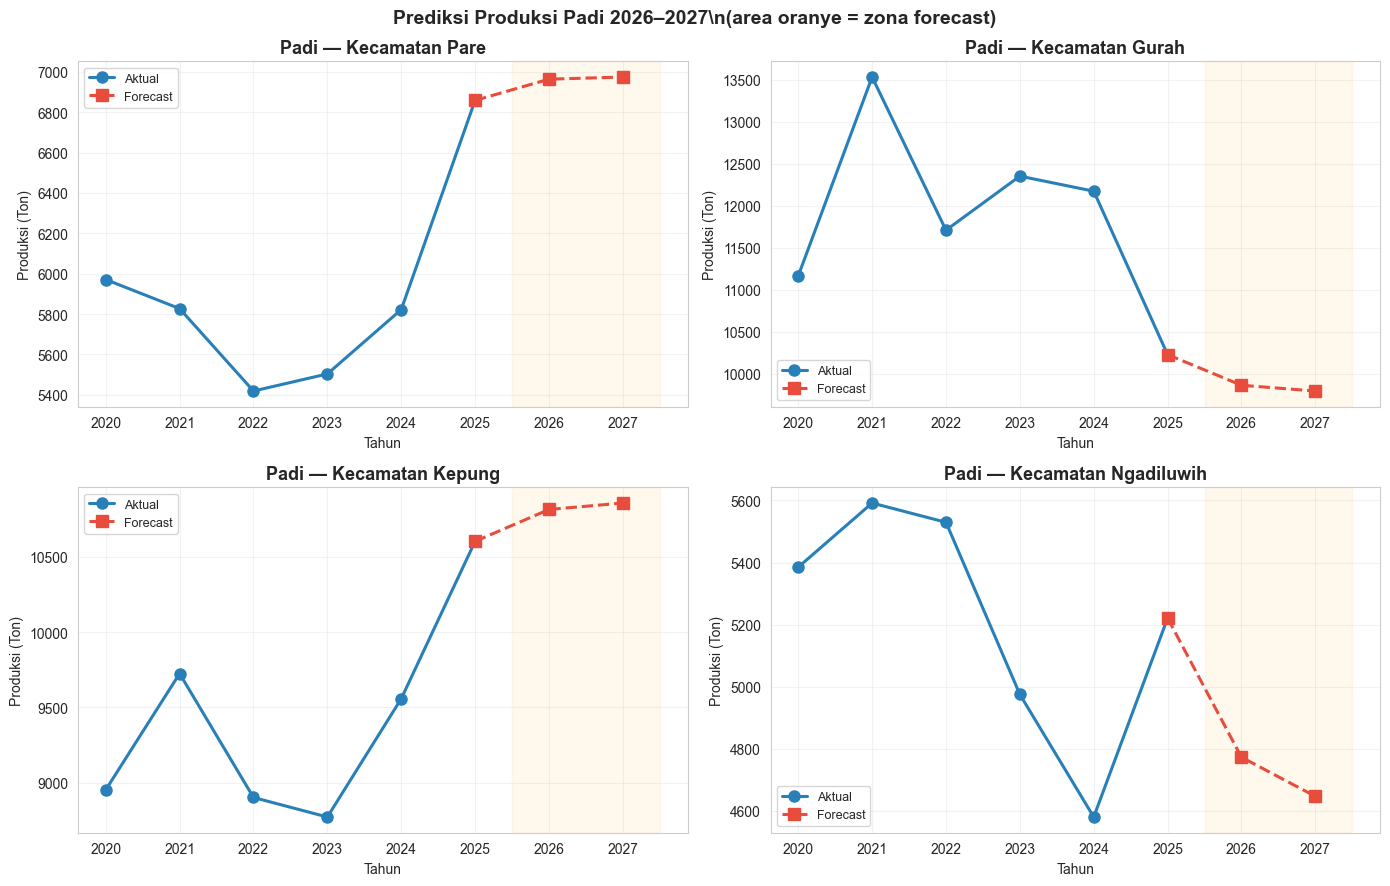

In [81]:
## 4.7 Visualisasi Contoh Prediksi

# ── Contoh: Padi di 4 kecamatan ──
kec_samples = ['Pare', 'Gurah', 'Kepung', 'Ngadiluwih']
target_col  = 'produksi_ton'

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes = axes.flatten()

for ax, kec in zip(axes, kec_samples):
    sample = final_ts_df[
        (final_ts_df['kecamatan'] == kec) &
        (final_ts_df['tanaman'] == 'Padi') &
        (final_ts_df['target'] == target_col)
    ]
    aktual   = sample[sample['tipe'] == 'aktual']
    forecast = sample[sample['tipe'] == 'forecast']

    ax.plot(aktual['Tahun'], aktual['nilai'], 'o-',
            color='#2980b9', label='Aktual', linewidth=2.2, markersize=8)
    if len(forecast) > 0:
        # Hubungkan garis
        last_yr  = aktual['Tahun'].iloc[-1]
        last_val = aktual['nilai'].iloc[-1]
        ax.plot([last_yr] + forecast['Tahun'].tolist(),
                [last_val] + forecast['nilai'].tolist(),
                's--', color='#e74c3c', label='Forecast', linewidth=2.2, markersize=8)
    ax.axvspan(2025.5, 2027.5, alpha=0.07, color='orange')
    ax.set_title(f'Padi — Kecamatan {kec}', fontweight='bold')
    ax.set_xlabel('Tahun'); ax.set_ylabel('Produksi (Ton)')
    ax.legend(fontsize=9); ax.grid(True, alpha=0.25)
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))

plt.suptitle('Prediksi Produksi Padi 2026–2027\\n(area oranye = zona forecast)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(OUTPUT_DIR + 'ts_02_sample_forecast_padi.png', dpi=150, bbox_inches='tight')
plt.show()

## 5. REKOMENDASI

### 4.1 Pendekatan: Bayesian Scoring

Skor rekomendasi dihitung dari **3 komponen** yang dinormalisasi ke [0, 1]:

| Komponen | Bobot | Makna |
|----------|-------|-------|
| Produksi rata-rata (ton/tahun) | **40%** | Volume komoditas yang dihasilkan |
| Produktivitas rata-rata (kw/ha) | **40%** | Efisiensi per satuan lahan |
| Growth rate produksi | **20%** | Tren perkembangan (naik/turun) |

**Formula:**  
`Skor = 0.4 × norm(prod_mean) + 0.4 × norm(produktivitas) + 0.2 × norm(growth_rate)`

In [82]:
# Hitung fitur agregat per (kecamatan, tanaman)
def last_val(x): return x.sort_values().iloc[-1]
def first_val(x): return x.sort_values().iloc[0]

agg_rek = df.groupby(['kecamatan','tanaman']).agg(
    prod_mean         = ('produksi_ton',            'mean'),
    prod_last         = ('produksi_ton',            last_val),
    prod_first        = ('produksi_ton',            first_val),
    produktivitas_mean= ('produktivitas_kuintal_ha','mean'),
    luas_mean         = ('luas_panen_ha',           'mean'),
    n_tahun           = ('Tahun',                   'count'),
).reset_index()

# Growth rate (produksi terakhir vs pertama)
agg_rek['growth_rate'] = (
    (agg_rek['prod_last'] - agg_rek['prod_first']) /
    (agg_rek['prod_first'].abs() + 1e-6)
).clip(-2.0, 10.0)

# Filter: hanya kombinasi yang benar-benar ada produksinya
agg_rek_valid = agg_rek[agg_rek['prod_mean'] > 0].copy()
print(f"Kombinasi dengan produksi > 0: {len(agg_rek_valid)} dari {len(agg_rek)}")
print()
print(agg_rek_valid[['kecamatan','tanaman','prod_mean','produktivitas_mean','growth_rate']].head(10).round(3).to_string(index=False))

Kombinasi dengan produksi > 0: 129 dari 130

kecamatan      tanaman  prod_mean  produktivitas_mean  growth_rate
    Badas Kacang Tanah       1.49               17.65         0.29
    Badas      Kedelai       2.72                4.24        10.00
    Badas Ketela Pohon      26.57              299.22         0.22
    Badas         Padi    9369.15               55.84         0.11
    Badas    Ubi Jalar      25.16              275.05         0.18
 Banyakan Kacang Tanah      82.67               18.28         0.15
 Banyakan      Kedelai       0.25               12.67         0.13
 Banyakan Ketela Pohon    1590.89              269.62         0.28
 Banyakan         Padi    4685.49               54.51         0.08
 Banyakan    Ubi Jalar    1653.04              313.39         0.14


In [83]:
# Normalize ke [0, 1]
mms = MinMaxScaler()
score_cols = ['prod_mean', 'produktivitas_mean', 'growth_rate']

norm_vals = mms.fit_transform(agg_rek_valid[score_cols].fillna(0))
norm_df   = pd.DataFrame(norm_vals, columns=[f'norm_{c}' for c in score_cols],
                          index=agg_rek_valid.index)
agg_rek_valid = pd.concat([agg_rek_valid, norm_df], axis=1)

In [84]:
# ── Bobot Bayesian ──
W_PROD  = 0.40
W_PROD_V= 0.40
W_GROW  = 0.20

agg_rek_valid['skor_rekomendasi'] = (
    W_PROD   * agg_rek_valid['norm_prod_mean'] +
    W_PROD_V * agg_rek_valid['norm_produktivitas_mean'] +
    W_GROW   * agg_rek_valid['norm_growth_rate']
).round(4)

print("Contoh skor rekomendasi (10 baris):")
print(agg_rek_valid[['kecamatan','tanaman','prod_mean','produktivitas_mean','growth_rate','skor_rekomendasi']]
      .sort_values('skor_rekomendasi', ascending=False).head(10).round(3).to_string(index=False))

## 5.2 Top-N Rekomendasi per Kecamatan

TOP_N = 3  # Jumlah rekomendasi per kecamatan

rekomendasi = (
    agg_rek_valid
    .sort_values(['kecamatan','skor_rekomendasi'], ascending=[True, False])
    .groupby('kecamatan')
    .head(TOP_N)
    .reset_index(drop=True)
)
rekomendasi['rank'] = rekomendasi.groupby('kecamatan').cumcount() + 1

print(f"TOP {TOP_N} REKOMENDASI TANAMAN PER KECAMATAN")
print("=" * 65)
for kec in sorted(rekomendasi['kecamatan'].unique()):
    sub = rekomendasi[rekomendasi['kecamatan'] == kec]
    items = [f"{row['tanaman']} ({row['skor_rekomendasi']:.3f})"
             for _, row in sub.iterrows()]
    print(f"  {kec:<18}: {' | '.join(items)}")

Contoh skor rekomendasi (10 baris):
kecamatan      tanaman  prod_mean  produktivitas_mean  growth_rate  skor_rekomendasi
 Plemahan         Padi   15583.83               57.78         0.15              0.48
    Semen Ketela Pohon    2515.38              311.93         0.29              0.46
    Puncu    Ubi Jalar    2259.27              306.82         0.52              0.45
   Kepung    Ubi Jalar    1904.76              318.03         0.19              0.45
     Mojo Ketela Pohon    3188.69              290.10         0.15              0.45
     Mojo    Ubi Jalar    2827.98              291.79         0.21              0.44
    Semen    Ubi Jalar    2090.13              304.78         0.20              0.44
 Banyakan    Ubi Jalar    1653.04              313.39         0.14              0.44
   Kepung Ketela Pohon    2398.54              288.17         0.28              0.43
    Puncu Ketela Pohon    2127.39              287.84         0.29              0.42
TOP 3 REKOMENDASI TANAMAN PER

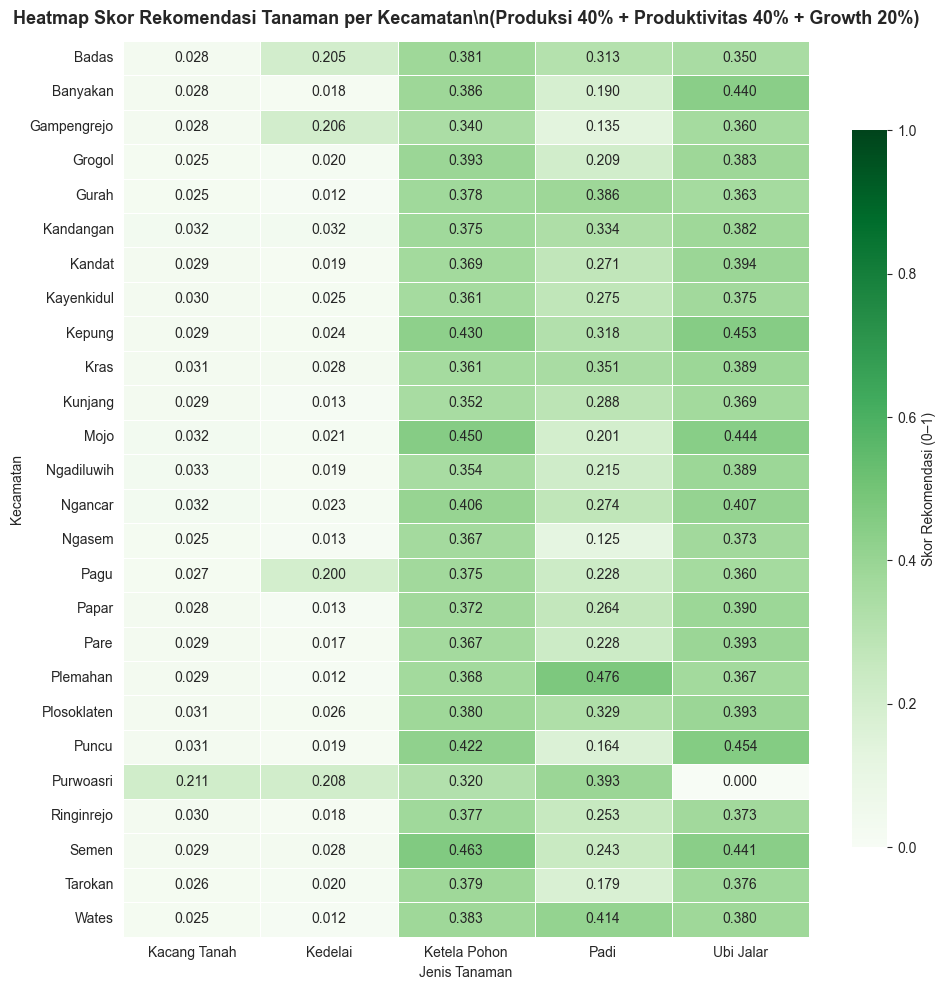

In [85]:
## 5.3 Heatmap Skor Rekomendasi

pivot_skor = agg_rek_valid.pivot(
    index='kecamatan', columns='tanaman', values='skor_rekomendasi'
).fillna(0)

fig, ax = plt.subplots(figsize=(10, 10))
sns.heatmap(pivot_skor, annot=True, fmt='.3f', cmap='Greens',
            linewidths=0.4, linecolor='white', ax=ax,
            cbar_kws={'label': 'Skor Rekomendasi (0–1)', 'shrink': 0.8},
            vmin=0, vmax=1)
ax.set_title(
    f'Heatmap Skor Rekomendasi Tanaman per Kecamatan\\n'
    f'(Produksi {int(W_PROD*100)}% + Produktivitas {int(W_PROD_V*100)}% + Growth {int(W_GROW*100)}%)',
    fontsize=13, fontweight='bold', pad=12
)
ax.set_xlabel('Jenis Tanaman'); ax.set_ylabel('Kecamatan')
plt.tight_layout()
plt.savefig(OUTPUT_DIR + 'rek_01_heatmap_skor.png', dpi=150, bbox_inches='tight')
plt.show()

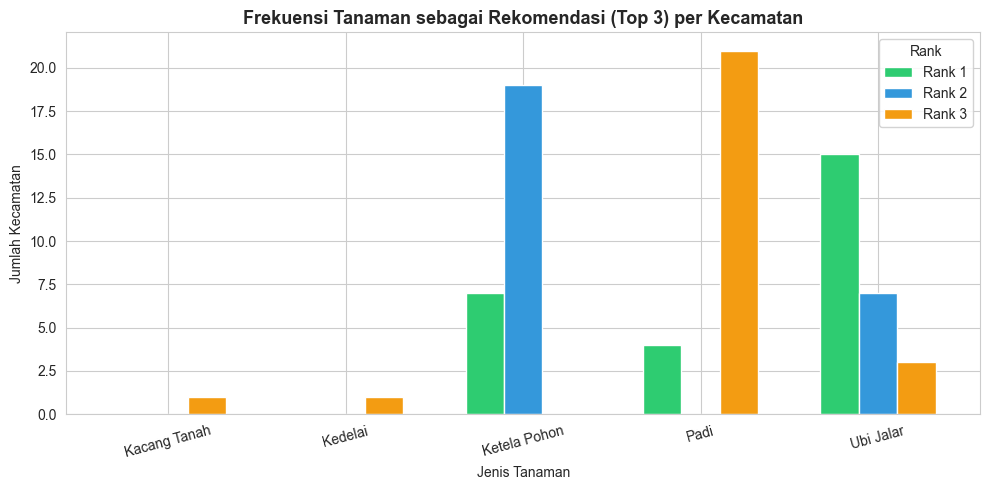

In [86]:
## 4.4 Stacked Bar — Distribusi Tanaman Unggulan

# Hitung berapa kali tiap tanaman jadi rekomendasi rank-1, rank-2, rank-3
rank_counts = rekomendasi.groupby(['tanaman','rank']).size().unstack(fill_value=0)
colors_bar  = ['#2ecc71','#3498db','#f39c12']

fig, ax = plt.subplots(figsize=(10, 5))
rank_counts.plot(kind='bar', ax=ax, color=colors_bar[:len(rank_counts.columns)],
                 edgecolor='white', width=0.65)
ax.set_title(f'Frekuensi Tanaman sebagai Rekomendasi (Top {TOP_N}) per Kecamatan',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Jenis Tanaman'); ax.set_ylabel('Jumlah Kecamatan')
ax.legend(title='Rank', labels=[f'Rank {r}' for r in rank_counts.columns], framealpha=0.85)
ax.tick_params(axis='x', rotation=15)
plt.tight_layout()
plt.savefig(OUTPUT_DIR + 'rek_02_distribusi_unggulan.png', dpi=150, bbox_inches='tight')
plt.show()

In [88]:
## 5.5 Export Output Rekomendasi

# Semua skor
out_all = OUTPUT_DIR + 'output_rekomendasi_all_scores.csv'
agg_rek_valid[['kecamatan','tanaman','prod_mean','produktivitas_mean',
               'growth_rate','luas_mean','skor_rekomendasi']].round(4).to_csv(out_all, index=False)

# Top-N per kecamatan
out_topn = OUTPUT_DIR + 'output_rekomendasi_pangan.csv'
rekomendasi[['kecamatan','tanaman','rank','skor_rekomendasi',
             'prod_mean','produktivitas_mean','growth_rate']].round(4).to_csv(out_topn, index=False)

print(f"✅ Semua skor   : {out_all}")
print(f"✅ Top-{TOP_N} per kec: {out_topn}")

✅ Semua skor   : ../output/output_rekomendasi_all_scores.csv
✅ Top-3 per kec: ../output/output_rekomendasi_pangan.csv


## 6. RINGKASAN

In [89]:
# Hasil ringkasan akhir
print("=" * 65)
print("   RINGKASAN HASIL PEMODELAN — TANAMAN PANGAN AGRIDASH")
print("=" * 65)

print("\\n[DATASET]")
print(f"   Periode  : 2020-2025 (6 tahun)")
print(f"   Tanaman  : {len(tanaman_list)} jenis | Kecamatan: {len(kecamatan_list)}")
print(f"   Baris    : {len(df):,}")
print("\\n[CLUSTERING]")
print(f"   Model utama  : K-Means (k={K_OPTIMAL})")
print(f"   Silhouette   : {sil_km:.4f}  |  Davies-Bouldin: {db_km:.4f}")
print(f"   Pembanding   : Agglomerative (Silhouette: {sil_agg:.4f})")
print(f"   Output       : output_clustering_pangan.csv")
print("\\n[PREDIKSI TIME SERIES]")
print(f"   Metode       : ETS / ARIMA / Linear Regression (terbaik per kombinasi)")
print(f"   MAPE ETS     : {comp_df['mape_ets'].mean():.2f}%")
print(f"   MAPE ARIMA   : {comp_df['mape_arima'].mean():.2f}%")
print(f"   MAPE Reg     : {comp_df['mape_lr'].mean():.2f}%")
print(f"   Forecast     : 2026-2027")
print(f"   Output       : output_timeseries_pangan.csv")
print("\\n[REKOMENDASI TANAMAN]")
print(f"   Model        : Bayesian Scoring (40% Prod + 40% Produktiv + 20% Growth)")
print(f"   Top-{TOP_N} per kec : {rekomendasi['kecamatan'].nunique()} kecamatan")
print(f"   Output       : output_rekomendasi_pangan.csv")

print("=" * 65)
print("   FILE OUTPUT UNTUK TABLEAU PUBLIC")
print("=" * 65)
import glob
files = glob.glob(OUTPUT_DIR + '*.csv')
print(f"\\n  📁 {os.path.abspath(OUTPUT_DIR)}")
for f in sorted(files):
    size = os.path.getsize(f) / 1024
    print(f"  ├── {os.path.basename(f):<45} {size:.1f} KB")
print("\\n✅ Semua output siap diimport ke Tableau Public!")


   RINGKASAN HASIL PEMODELAN — TANAMAN PANGAN AGRIDASH
\n[DATASET]
   Periode  : 2020-2025 (6 tahun)
   Tanaman  : 5 jenis | Kecamatan: 26
   Baris    : 780
\n[CLUSTERING]
   Model utama  : K-Means (k=4)
   Silhouette   : 0.4684  |  Davies-Bouldin: 0.6687
   Pembanding   : Agglomerative (Silhouette: 0.4684)
   Output       : output_clustering_pangan.csv
\n[PREDIKSI TIME SERIES]
   Metode       : ETS / ARIMA / Linear Regression (terbaik per kombinasi)
   MAPE ETS     : 9.11%
   MAPE ARIMA   : 8.35%
   MAPE Reg     : 8.51%
   Forecast     : 2026-2027
   Output       : output_timeseries_pangan.csv
\n[REKOMENDASI TANAMAN]
   Model        : Bayesian Scoring (40% Prod + 40% Produktiv + 20% Growth)
   Top-3 per kec : 26 kecamatan
   Output       : output_rekomendasi_pangan.csv
   FILE OUTPUT UNTUK TABLEAU PUBLIC
\n  📁 d:\SDT\Project Analitika Data\AgriDash-0.1\output
  ├── output_clustering_pangan.csv                  3.5 KB
  ├── output_model_comparison.csv                   25.1 KB
  ├── ou

In [90]:
# ── Notebook metadata ──────────────────────────────────────────
nb = {
    "nbformat": 4,
    "nbformat_minor": 5,
    "metadata": {
        "kernelspec": {
            "display_name": "Python 3",
            "language": "python",
            "name": "python3"
        },
        "language_info": {
            "codemirror_mode": {"name": "ipython", "version": 3},
            "file_extension": ".py",
            "mimetype": "text/x-python",
            "name": "python",
            "pygments_lexer": "ipython3",
            "version": "3.10.0"
        }
    },
    "cells": cells
}

NOTEBOOK_DIR = os.path.join(BASE, 'notebooks')
out = os.path.join(NOTEBOOK_DIR, '01_Modeling_Tanaman_Pangan.ipynb')
with open(out, 'w', encoding='utf-8') as f:
    json.dump(nb, f, ensure_ascii=False, indent=1)

print(f"✅ Notebook berhasil dibuat!")
print(f"   Path: {out}")
print(f"   Jumlah cell: {len(cells)}")

FileNotFoundError: [Errno 2] No such file or directory: 'd:\\SDT\\Project Analitika Data\\AgriDash-0.1\\notebooks\\notebooks\\01_Modeling_Tanaman_Pangan.ipynb'